In [ ]:
import pandas as pd
import random, numpy as np, torch

SEED = 33
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)

In [8]:
# Split the train / dev / test set 
import json

splits = {"train": [], "dev": [], "test": []}
with open("en-US.jsonl", "r") as f:
    for line in f:
        data = json.loads(line)
        if data["partition"] == "train":
            splits["train"].append(data)
        elif data["partition"] == "dev":
            splits["dev"].append(data)
        elif data["partition"] == "test":
            splits["test"].append(data)

print(f"Train set size: {len(splits['train'])}")
print(f"Dev set size: {len(splits['dev'])}")
print(f"Test set size: {len(splits['test'])}")

Train set size: 11514
Dev set size: 2033
Test set size: 2974


In [16]:
# Count the intents
from collections import Counter

intent_counter = Counter()
for split in splits.values():
    for data in split:
        intent_counter[data["intent"]] += 1

print("Intent counts:")
for intent, count in intent_counter.items():
    print(f"  {intent}: {count}")

print(f"Total number of intents: {len(intent_counter)}")
print(f"Total number of examples: {sum(intent_counter.values())}")

Intent counts:
  alarm_set: 254
  audio_volume_mute: 157
  iot_hue_lightchange: 183
  iot_hue_lightoff: 213
  iot_hue_lightdim: 114
  iot_cleaning: 138
  calendar_query: 794
  play_music: 938
  general_quirky: 829
  general_greet: 28
  datetime_query: 502
  datetime_convert: 76
  takeaway_query: 181
  alarm_remove: 113
  alarm_query: 183
  news_query: 709
  music_likeness: 165
  music_query: 219
  iot_hue_lightup: 115
  takeaway_order: 177
  weather_query: 855
  music_settings: 65
  general_joke: 106
  music_dislikeness: 20
  audio_volume_other: 24
  iot_coffee: 174
  audio_volume_up: 135
  iot_wemo_on: 65
  iot_hue_lighton: 30
  iot_wemo_off: 75
  audio_volume_down: 71
  qa_stock: 202
  play_radio: 401
  recommendation_locations: 235
  qa_factoid: 775
  calendar_set: 1150
  play_audiobook: 226
  play_podcasts: 290
  social_query: 151
  transport_query: 314
  email_sendemail: 531
  recommendation_movies: 102
  lists_query: 299
  play_game: 169
  transport_ticket: 187
  recommendation_e

In [17]:
all_records = splits["train"] + splits["dev"] + splits["test"]

df = pd.DataFrame(all_records)
print(pd.crosstab(df["intent"], df["partition"], margins=True))

partition           dev  test  train    All
intent                                     
alarm_query          19    34    130    183
alarm_remove         14    21     78    113
alarm_set            31    41    182    254
audio_volume_down     8    11     52     71
audio_volume_mute    15    32    110    157
...                 ...   ...    ...    ...
transport_taxi       27    23    100    150
transport_ticket     25    35    127    187
transport_traffic    22    15    117    154
weather_query       126   156    573    855
All                2033  2974  11514  16521

[61 rows x 4 columns]


In [ ]:
# 1. Count the intents in training data
train_intent_counter = Counter(r["intent"] for r in splits["train"])

print("Train intent counts:")
for intent, count in train_intent_counter.most_common():
    print(f"  {intent}: {count}")

print(f"Number of intents in train: {len(train_intent_counter)}")
print(f"Total train examples: {sum(train_intent_counter.values())}")

Train intent counts:
  calendar_set: 810
  play_music: 639
  weather_query: 573
  calendar_query: 566
  general_quirky: 555
  qa_factoid: 544
  news_query: 503
  email_query: 418
  email_sendemail: 354
  datetime_query: 350
  calendar_remove: 312
  play_radio: 283
  social_post: 283
  qa_definition: 267
  transport_query: 227
  cooking_recipe: 207
  lists_query: 198
  play_podcasts: 193
  recommendation_events: 190
  alarm_set: 182
  lists_createoradd: 177
  recommendation_locations: 173
  lists_remove: 164
  music_query: 154
  iot_hue_lightoff: 153
  qa_stock: 152
  play_audiobook: 150
  qa_currency: 142
  takeaway_order: 135
  alarm_query: 130
  transport_ticket: 127
  email_querycontact: 127
  iot_hue_lightchange: 125
  iot_coffee: 124
  takeaway_query: 122
  transport_traffic: 117
  music_likeness: 113
  play_game: 112
  audio_volume_mute: 110
  audio_volume_up: 110
  social_query: 108
  transport_taxi: 100
  iot_cleaning: 93
  alarm_remove: 78
  qa_maths: 78
  iot_hue_lightdim: 76

In [ ]:
# 2. Seeing the slot types and their counts in training data
import re

SLOT_RE = re.compile(r"\[([^\[\]:]+?)\s*:\s*([^\[\]]+?)\]")

slot_counts = Counter()
for r in splits["train"]:
    for slot_type, span in SLOT_RE.findall(r["annot_utt"]):
        slot_counts[slot_type.strip()] += 1

print("Number of slot types:", len(slot_counts))
for s, n in slot_counts.most_common():
    print(f"{s:30s} {n}")

Number of slot types: 55
date                           1816
place_name                     1086
event_name                     998
person                         864
time                           797
media_type                     477
business_name                  383
weather_descriptor             320
transport_type                 318
food_type                      295
relation                       251
timeofday                      239
artist_name                    232
device_type                    226
definition_word                225
currency_name                  217
house_place                    198
list_name                      191
business_type                  189
news_topic                     183
music_genre                    181
player_setting                 160
radio_name                     131
song_name                      128
order_type                     107
color_type                     100
game_name                      87
general_frequency            

Mean:            6.92
Median:          6
Max:             35
95th percentile: 13


Matplotlib is building the font cache; this may take a moment.


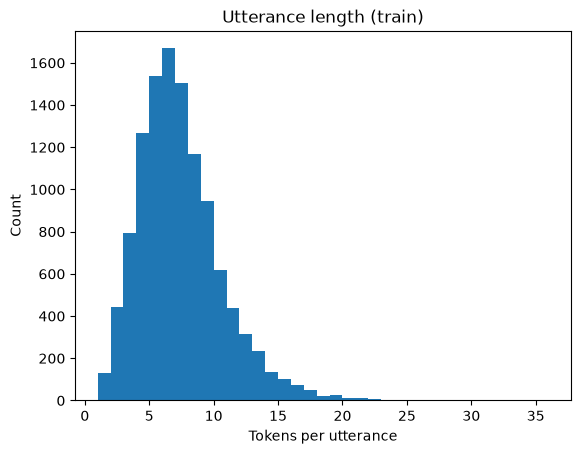

In [ ]:
# 3. Utterance length in training data
lengths = np.array([len(r["utt"].split()) for r in splits["train"]])

print(f"Mean:            {lengths.mean():.2f}")
print(f"Median:          {np.median(lengths):.0f}")
print(f"Max:             {lengths.max()}")
print(f"95th percentile: {np.percentile(lengths, 95):.0f}")

import matplotlib.pyplot as plt
plt.hist(lengths, bins=range(1, lengths.max() + 2))
plt.xlabel("Tokens per utterance"); plt.ylabel("Count")
plt.title("Utterance length (train)")
plt.show()

In [22]:
# 4. Slot per utterance in training data
per_utt = Counter(min(len(SLOT_RE.findall(r["annot_utt"])), 2) for r in splits["train"])
print("0 slots:", per_utt[0], "| 1 slot:", per_utt[1], "| 2+ slots:", per_utt[2])

0 slots: 3755 | 1 slot: 5074 | 2+ slots: 2685


In [ ]:

# 5. Slot spans in training data
import re
from collections import Counter

SLOT_RE = re.compile(r"\[([^\[\]:]+?)\s*:\s*([^\[\]]+?)\]")

span_lengths = [
    len(span.split())
    for r in splits["train"]
    for _, span in SLOT_RE.findall(r["annot_utt"])
]

total = len(span_lengths)
single = sum(1 for n in span_lengths if n == 1)
multi = total - single

print(f"Total slot spans: {total}")
print(f"Single-word:      {single} ({100 * single / total:.2f}%)")
print(f"Multi-word:       {multi} ({100 * multi / total:.2f}%)")

# Breakdown by exact length
for n, c in sorted(Counter(span_lengths).items()):
    print(f"  {n} word(s): {c}")


Total slot spans: 11344
Single-word:      7008 (61.78%)
Multi-word:       4336 (38.22%)
  1 word(s): 7008
  2 word(s): 2903
  3 word(s): 993
  4 word(s): 202
  5 word(s): 131
  6 word(s): 60
  7 word(s): 35
  8 word(s): 6
  9 word(s): 3
  10 word(s): 3


In [23]:
# 6. Number of unique words, and how many appear only once? (training data)
word_counts = Counter(w for r in splits["train"] for w in r["utt"].split())
print("Unique words:", len(word_counts))
print("Appear once:", sum(1 for c in word_counts.values() if c == 1))

Unique words: 5302
Appear once: 2537


In [24]:
# 7. Odd characters in training data (apostrophes, hyphens, digits, symbols)
import string
odd = Counter(ch for r in splits["train"] for ch in r["utt"]
              if not (ch.isalpha() or ch == " "))
print(odd.most_common())

[('.', 1299), ("'", 952), ('-', 35), ('&', 5), ('<', 1), ('>', 1)]


In [25]:
# 8. Do different intents use different slots? (training data)
from collections import defaultdict
intent_slots = defaultdict(Counter)
for r in splits["train"]:
    for t, _ in SLOT_RE.findall(r["annot_utt"]):
        intent_slots[r["intent"]][t.strip()] += 1
for intent, c in list(intent_slots.items())[:5]:
    print(intent, dict(c.most_common(5)))

alarm_set {'time': 141, 'date': 53, 'timeofday': 24, 'event_name': 21, 'general_frequency': 2}
audio_volume_mute {'time': 22, 'device_type': 4, 'change_amount': 2, 'timeofday': 1, 'event_name': 1}
iot_hue_lightchange {'color_type': 98, 'house_place': 34, 'change_amount': 5, 'player_setting': 1, 'time': 1}
iot_hue_lightoff {'house_place': 91, 'device_type': 22, 'time': 4, 'color_type': 1}
iot_hue_lightdim {'house_place': 21, 'change_amount': 9, 'device_type': 1, 'color_type': 1}
